In [115]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

In [4]:
customerShopping_df = pd.read_excel('/content/Data_Science.xlsx')
customerShopping_df.head()

,Transaction_ID,Customer_Name,City,Department,Product,Quantity,Unit_Price,Revenue,Expense,Profit,Customer_Rating,Customer_Feedback,Employee_Performance_Score,Payment_Method,Purchase_Date
0,TXN00001,Maria Dominguez,Hyderabad,HR,Headphones,2,69623,139246,79676,59570,1,Poor,98,Net Banking,2024-10-23
1,TXN00002,Jasmine Wells,Mumbai,Sales,Keyboard,3,5478,16434,7198,9236,4,Excellent,53,Net Banking,2024-06-04
2,TXN00003,Sherri Brown,Delhi,Finance,Tablet,8,2629,21032,12831,8201,2,Average,76,Net Banking,2024-11-22
3,TXN00004,Dr. Lisa Garcia,Mumbai,IT,Mobile,5,49088,245440,131238,114202,2,Good,86,Card,2024-03-28
4,TXN00005,Kelly Carpenter,Delhi,IT,Smartwatch,10,17066,170660,104544,66116,4,Poor,90,UPI,2024-02-06


In [6]:
customerShopping_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Transaction_ID              8000 non-null   object
 1   Customer_Name               8000 non-null   object
 2   City                        8000 non-null   object
 3   Department                  8000 non-null   object
 4   Product                     8000 non-null   object
 5   Quantity                    8000 non-null   int64 
 6   Unit_Price                  8000 non-null   int64 
 7   Revenue                     8000 non-null   int64 
 8   Expense                     8000 non-null   int64 
 9   Profit                      8000 non-null   int64 
 10  Customer_Rating             8000 non-null   int64 
 11  Customer_Feedback           8000 non-null   object
 12  Employee_Performance_Score  8000 non-null   int64 
 13  Payment_Method              8000 non-null   obje

In [7]:
customerShopping_df.isnull().sum()

,0
Transaction_ID,0
Customer_Name,0
City,0
Department,0
Product,0
Quantity,0
Unit_Price,0
Revenue,0
Expense,0
Profit,0


In [8]:
customerShopping_df.duplicated().sum()

np.int64(0)

In [9]:
customerShopping_df.describe()

,Quantity,Unit_Price,Revenue,Expense,Profit,Customer_Rating,Employee_Performance_Score
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,5.489875,39986.185250,220579.671250,143603.016125,76976.655125,2.974000,75.047500
std,2.867564,22816.835733,184033.861201,127191.071525,76480.501085,1.406706,14.809057
min,1.000000,512.000000,556.000000,335.000000,180.000000,1.000000,50.000000
25%,3.000000,19996.000000,67909.500000,43332.000000,20328.500000,2.000000,62.000000
50%,5.000000,39939.500000,166532.000000,105032.500000,51473.500000,3.000000,75.000000
75%,8.000000,59629.750000,335917.250000,212453.000000,109249.500000,4.000000,88.000000
max,10.000000,79993.000000,798410.000000,714389.000000,478595.000000,5.000000,100.000000


In [10]:
customerShopping_df = customerShopping_df.drop(['Transaction_ID','Customer_Name'], axis=1)

In [11]:
customerShopping_df['Purchase_Date'] = pd.to_datetime(customerShopping_df['Purchase_Date'])

In [84]:
X = customerShopping_df.drop("Revenue", axis=1)
y = customerShopping_df["Revenue"]

num_cols = ['Quantity','Unit_Price']
cat_cols = ['City',	'Department',	'Product','Payment_Method']

In [85]:
# train Test Split

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((6400, 12), (1600, 12), (6400,), (1600,))

In [86]:
numeric_pipeline = Pipeline([
    ("scaler", StandardScaler())
])
numeric_pipeline

categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [110]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols)
])

LR_Model = Pipeline(steps=[
    ('Preprocess_Step', preprocessor),
    ('Classifier', LinearRegression())
])

LR_Model.fit(X_train, y_train)

Pipeline(steps=[('Preprocess_Step',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['Quantity', 'Unit_Price']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['City', 'Department',
                                                   'Product',
                                                   'Payment_Method'])])),
                ('Classifier', LinearRegression())])

In [112]:
y_pred_train=LR_Model.predict(X_train)
y_pred_test=LR_Model.predict(X_test)

In [166]:
# Evaluate Train Performance
print("Linear Regression Evaluation Report : ")
train_mse = mean_squared_error(y_train, y_pred_train)
train_rmse = np.sqrt(train_mse)
train_mae = mean_absolute_error(y_train, y_pred_train)
train_r2 = r2_score(y_train, y_pred_train)

print(f"Train RMSE: {train_rmse:.2f}")
print(f"Train MAE:  {train_mae:.2f}")
print(f"Train R²:   {train_r2:.4f}\n")

# Evaluate Test Performance
test_mse = mean_squared_error(y_test, y_pred_test)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(y_test, y_pred_test)
test_r2 = r2_score(y_test, y_pred_test)

print(f"Test RMSE: {test_rmse:.2f}")
print(f"Test MAE:  {test_mae:.2f}")
print(f"Test R²:   {test_r2:.4f}")

Linear Regression Evaluation Report : 
Train RMSE: 65227.64
Train MAE:  49187.81
Train R²:   0.8741

Test RMSE: 66313.40
Test MAE:  49813.07
Test R²:   0.8711


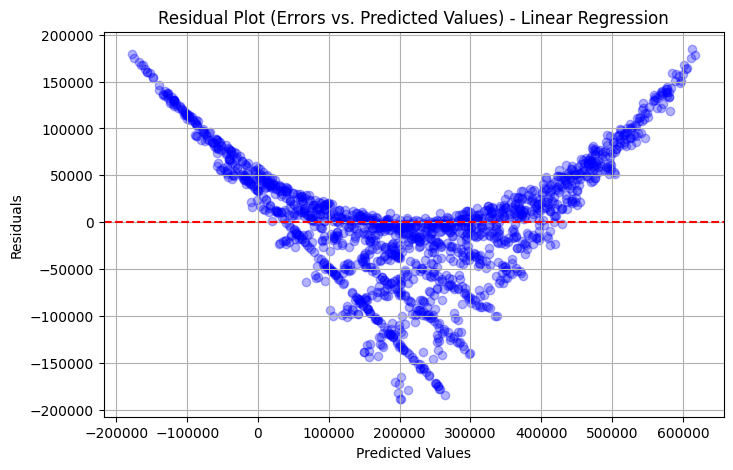

In [120]:

residuals = y_test - y_pred_test

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_test, residuals, alpha=0.3, color='blue')
plt.axhline(0, color='red', linestyle='--')
plt.title("Residual Plot (Errors vs. Predicted Values) - Linear Regression")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.grid(True)
plt.show()

In [121]:
from sklearn.ensemble import RandomForestRegressor

RF_Model=Pipeline(steps=[
    ('Preprocess_Step',preprocessor),
    ('Classifier',RandomForestRegressor(n_estimators=100, random_state=42))
])
RF_Model

RF_Model.fit(X_train, y_train)

Pipeline(steps=[('Preprocess_Step',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['Quantity', 'Unit_Price']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['City', 'Department',
                                                   'Product',
                                                   'Payment_Method'])])),
                ('Classifier', RandomForestRegressor(random_state=42))])

In [144]:
rf_pred_train=RF_Model.predict(X_train)
rf_pred_test=RF_Model.predict(X_test)

In [146]:
# Evaluate Train Performance
print("Random Forest Evaluation Report : ")

train_mse = mean_squared_error(y_train, rf_pred_train)
train_rmse = np.sqrt(train_mse)
train_mae = mean_absolute_error(y_train, rf_pred_train)
train_r2 = r2_score(y_train, rf_pred_train)

print(f"Train RMSE: {train_rmse:.2f}")
print(f"Train MAE:  {train_mae:.2f}")
print(f"Train R²:   {train_r2:.4f}\n")

# Evaluate Test Performance
test_mse = mean_squared_error(y_test, rf_pred_test)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(y_test, rf_pred_test)
test_r2 = r2_score(y_test, rf_pred_test)

print(f"Test RMSE: {test_rmse:.2f}")
print(f"Test MAE:  {test_mae:.2f}")
print(f"Test R²:   {test_r2:.4f}")

Random Forest Evaluation Report : 
Train RMSE: 271.57
Train MAE:  171.03
Train R²:   1.0000

Test RMSE: 684.87
Test MAE:  426.55
Test R²:   1.0000


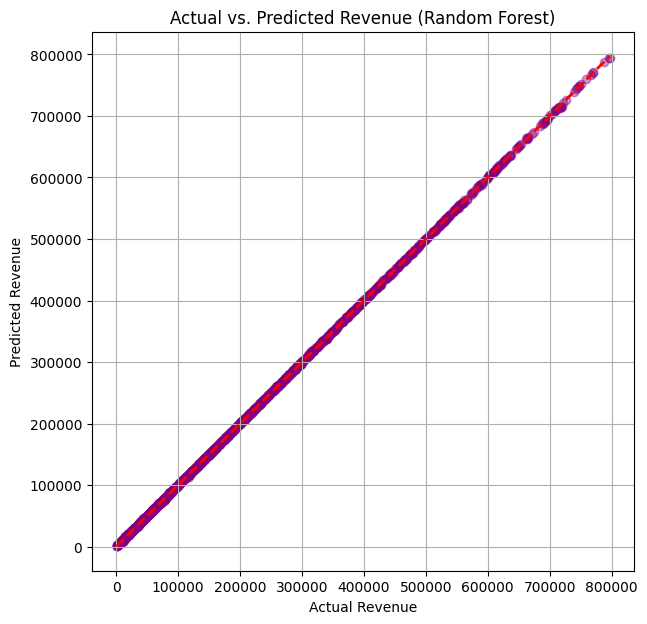

In [123]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, rf_pred_test, alpha=0.4, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs. Predicted Revenue (Random Forest)")
plt.grid(True)
plt.show()

In [124]:
from sklearn.tree import DecisionTreeRegressor

dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(random_state=42))
])

dt_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['Quantity', 'Unit_Price']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['City', 'Department',
                                                   'Product',
                                                   'Payment_Method'])])),
                ('regressor', DecisionTreeRegressor(random_state=42))])

In [148]:
dt_pred_train=dt_pipeline.predict(X_train)
dt_pred_test=dt_pipeline.predict(X_test)

In [151]:
# Evaluate Train Performance
print("Decision Tree Regressor Evaluation Report : ")

train_mse = mean_squared_error(y_train, dt_pred_train)
train_rmse = np.sqrt(train_mse)
train_mae = mean_absolute_error(y_train, dt_pred_train)
train_r2 = r2_score(y_train, dt_pred_train)

print(f"Train RMSE: {train_rmse:.2f}")
print(f"Train MAE:  {train_mae:.2f}")
print(f"Train R²:   {train_r2:.4f}\n")

# Evaluate Test Performance
test_mse = mean_squared_error(y_test, dt_pred_test)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(y_test, dt_pred_test)
test_r2 = r2_score(y_test, dt_pred_test)

print(f"Test RMSE: {test_rmse:.2f}")
print(f"Test MAE:  {test_mae:.2f}")
print(f"Test R²:   {test_r2:.4f}")

Decision Tree Regressor Evaluation Report : 
Train RMSE: 0.00
Train MAE:  0.00
Train R²:   1.0000

Test RMSE: 1272.30
Test MAE:  759.02
Test R²:   1.0000


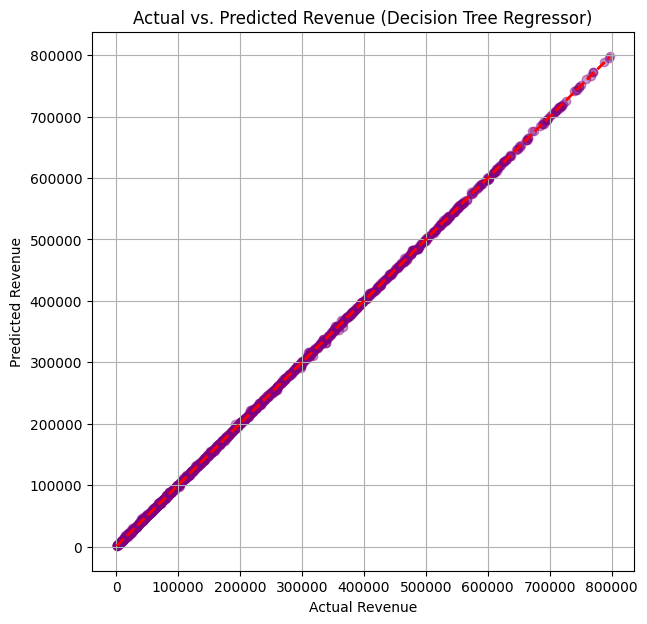

In [152]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, dt_pred_test, alpha=0.4, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs. Predicted Revenue (Decision Tree Regressor)")
plt.grid(True)
plt.show()

In [163]:
from sklearn.neighbors import KNeighborsRegressor

knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', KNeighborsRegressor())
])

knn_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['Quantity', 'Unit_Price']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['City', 'Department',
                                                   'Product',
                                                   'Payment_Method'])])),
                ('regressor', KNeighborsRegressor())])

In [164]:
knn_pred_train=knn_pipeline.predict(X_train)
knn_pred_test=knn_pipeline.predict(X_test)

In [165]:
# Evaluate Train Performance
print("K Neighbors Regressor Evaluation Report : ")

train_mse = mean_squared_error(y_train, knn_pred_train)
train_rmse = np.sqrt(train_mse)
train_mae = mean_absolute_error(y_train, knn_pred_train)
train_r2 = r2_score(y_train, knn_pred_train)

print(f"Train RMSE: {train_rmse:.2f}")
print(f"Train MAE:  {train_mae:.2f}")
print(f"Train R²:   {train_r2:.4f}\n")

# Evaluate Test Performance
test_mse = mean_squared_error(y_test, knn_pred_test)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(y_test, knn_pred_test)
test_r2 = r2_score(y_test, knn_pred_test)

print(f"Test RMSE: {test_rmse:.2f}")
print(f"Test MAE:  {test_mae:.2f}")
print(f"Test R²:   {test_r2:.4f}")

K Neighbors Regressor Evaluation Report : 
Train RMSE: 45185.84
Train MAE:  33764.75
Train R²:   0.9396

Test RMSE: 49791.77
Test MAE:  37570.25
Test R²:   0.9273


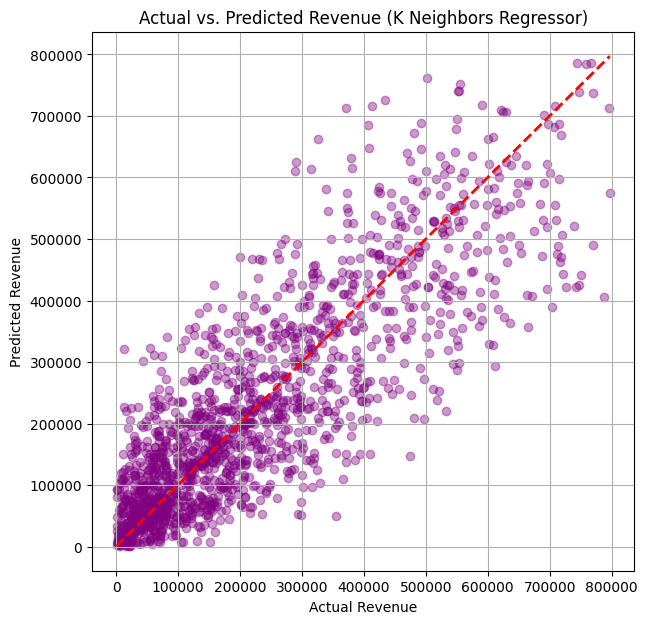

In [141]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, knn_pred_test, alpha=0.4, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs. Predicted Revenue (K Neighbors Regressor)")
plt.grid(True)
plt.show()

In [130]:
joblib.dump(RF_Model, 'sales_prediction_rf_model.pkl')
joblib.dump(dt_pipeline, 'sales_prediction_dt_model.pkl')
joblib.dump(knn_pipeline, 'sales_prediction_knn_model.pkl')

['sales_prediction_knn_model.pkl']

In [140]:
from google.colab import files
files.download('sales_prediction_rf_model.pkl')
files.download('sales_prediction_dt_model.pkl')
files.download('sales_prediction_knn_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [168]:
loaded_model = joblib.load('sales_prediction_rf_model.pkl')

new_data = pd.DataFrame([{
    'Quantity': 2,
    'Unit_Price': 606,
    'Product': 'Monitor',
    'City': 'Hyderabad',
    'Department': 'Marketing',
    'Payment_Method': 'Cash'
}])

predicted_revenue = loaded_model.predict(new_data)
print(f"Predicted Revenue: ₹{predicted_revenue[0]:,.2f}")

Predicted Revenue: ₹1,606.52


In [135]:
import joblib

loaded_model = joblib.load('sales_prediction_dt_model.pkl')

new_data = pd.DataFrame([{
    'Quantity': 4,
    'Unit_Price': 548,
    'Product': 'Monitor',
    'City': 'Bangalore',
    'Department': 'IT',
    'Payment_Method': 'Card'
}])

predicted_revenue = loaded_model.predict(new_data)
print(f"Predicted Revenue: ₹{predicted_revenue[0]:,.2f}")

Predicted Revenue: ₹2,144.00


In [136]:
import joblib

loaded_model = joblib.load('sales_prediction_knn_model.pkl')

new_data = pd.DataFrame([{
    'Quantity': 4,
    'Unit_Price': 548,
    'Product': 'Monitor',
    'City': 'Bangalore',
    'Department': 'IT',
    'Payment_Method': 'Card'
}])

predicted_revenue = loaded_model.predict(new_data)
print(f"Predicted Revenue: ₹{predicted_revenue[0]:,.2f}")

Predicted Revenue: ₹8,004.00
